# Analysis — Many Particles


## Configuração

Edite apenas esta célula para adicionar/remover partículas ou frequências.


In [1]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np

np.seterr("warn")

from treament_tcspc_data import (
    fetch_data_filenames,
    extract_data_info_from_path,
    get_xf_yf_fund,
    get_mean_amp_and_phase,
    time_domain_visual_verification,
    # get_fft,
)
from snr_aux_functions import get_snr_db, plot_time_and_freq_domain

In [2]:
filenames_all = fetch_data_filenames("./raw-data/")

In [3]:
exc_data_npy = sorted(
    [
        extract_data_info_from_path(data_path_npy)
        for data_path_npy in filenames_all
        if (
            ("step" in data_path_npy)
            and ("raw-data/laser/exc_laser100mA_counts33k" in data_path_npy)
            and ("_0.5V_0.4offs.npy" in data_path_npy)
        )
    ],
    key=lambda d: d["freq"],
)

In [4]:
SAMPLES_LIST = {
    "Y2O3: Yb/Er 50mA": {
        "lum_path": "raw-data/y2o3-yber-1M-pwd-50mA/sine/amp_5e-1_offset_4e-1/lum_laser50mA_counts18k"
    },
    "Y2O3: Yb/Er 200mA": {
        "lum_path": "raw-data/y2o3-yber-1M-pwd-200mA/varying_amp_offset_4e-1/lum_laser200mA_counts35k_OD_15e-2"
    },
    "Y2O3: Yb/Er 800mA": {
        "lum_path": "raw-data/y2o3-yber-1M-pwd-800mA/lum_laser800mA_counts30k_OD_23e-2"
    },
}

In [5]:
# Populate particle list
samples_list = [
    {
        "sample_label": sample,
        "sample_data": sorted(
            [
                extract_data_info_from_path(data_path_npy)
                for data_path_npy in filenames_all
                if (
                    ("step" in data_path_npy)
                    and ("lum_laser" in data_path_npy)
                    and ("_0.5V_0.4offs.npy" in data_path_npy)
                    and (SAMPLES_LIST[sample]["lum_path"] in data_path_npy)
                )
            ],
            key=lambda d: d["freq"],
        ),
    }
    for sample in SAMPLES_LIST
]

## Análise — loop sobre N partículas


### Plot all



  Processing Y2O3: Yb/Er 50mA  


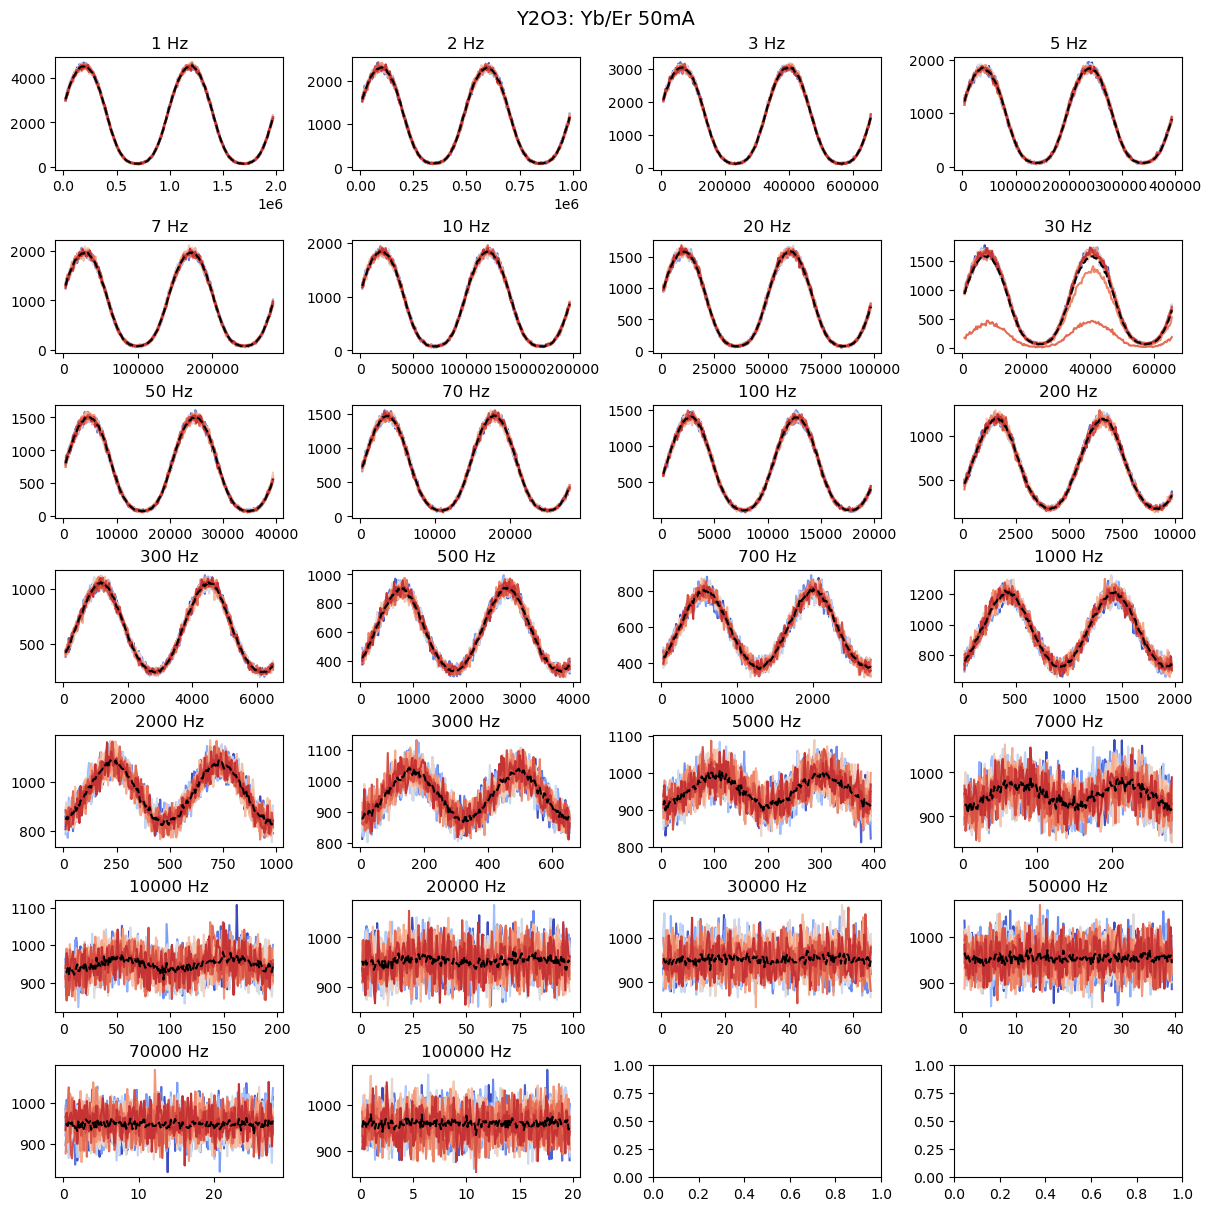


  Processing Y2O3: Yb/Er 200mA  


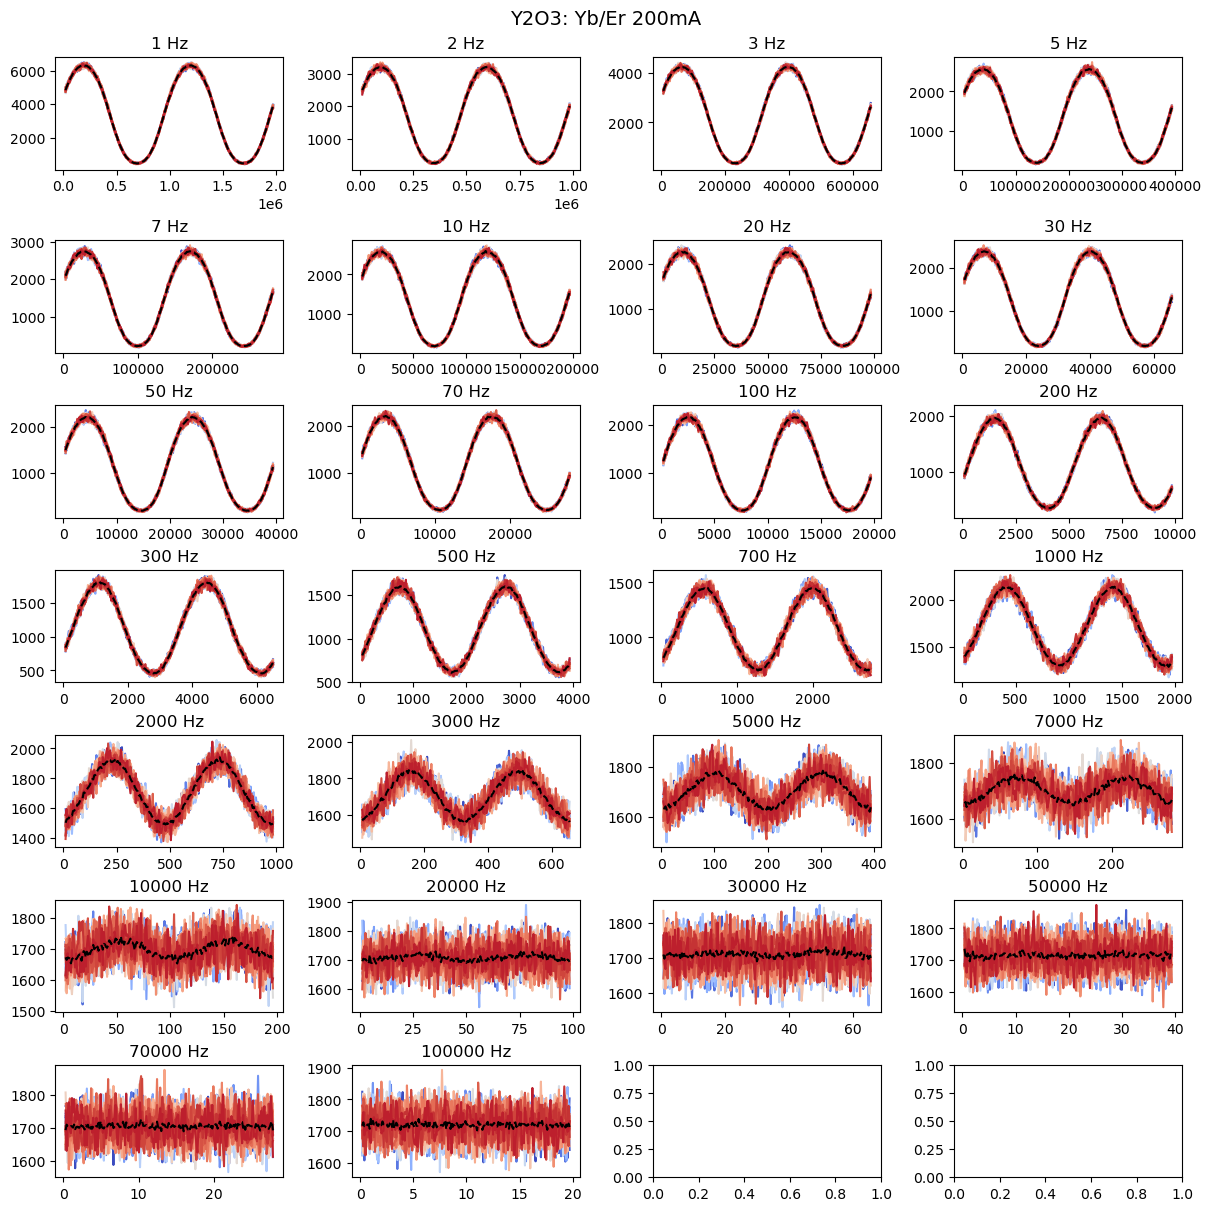


  Processing Y2O3: Yb/Er 800mA  


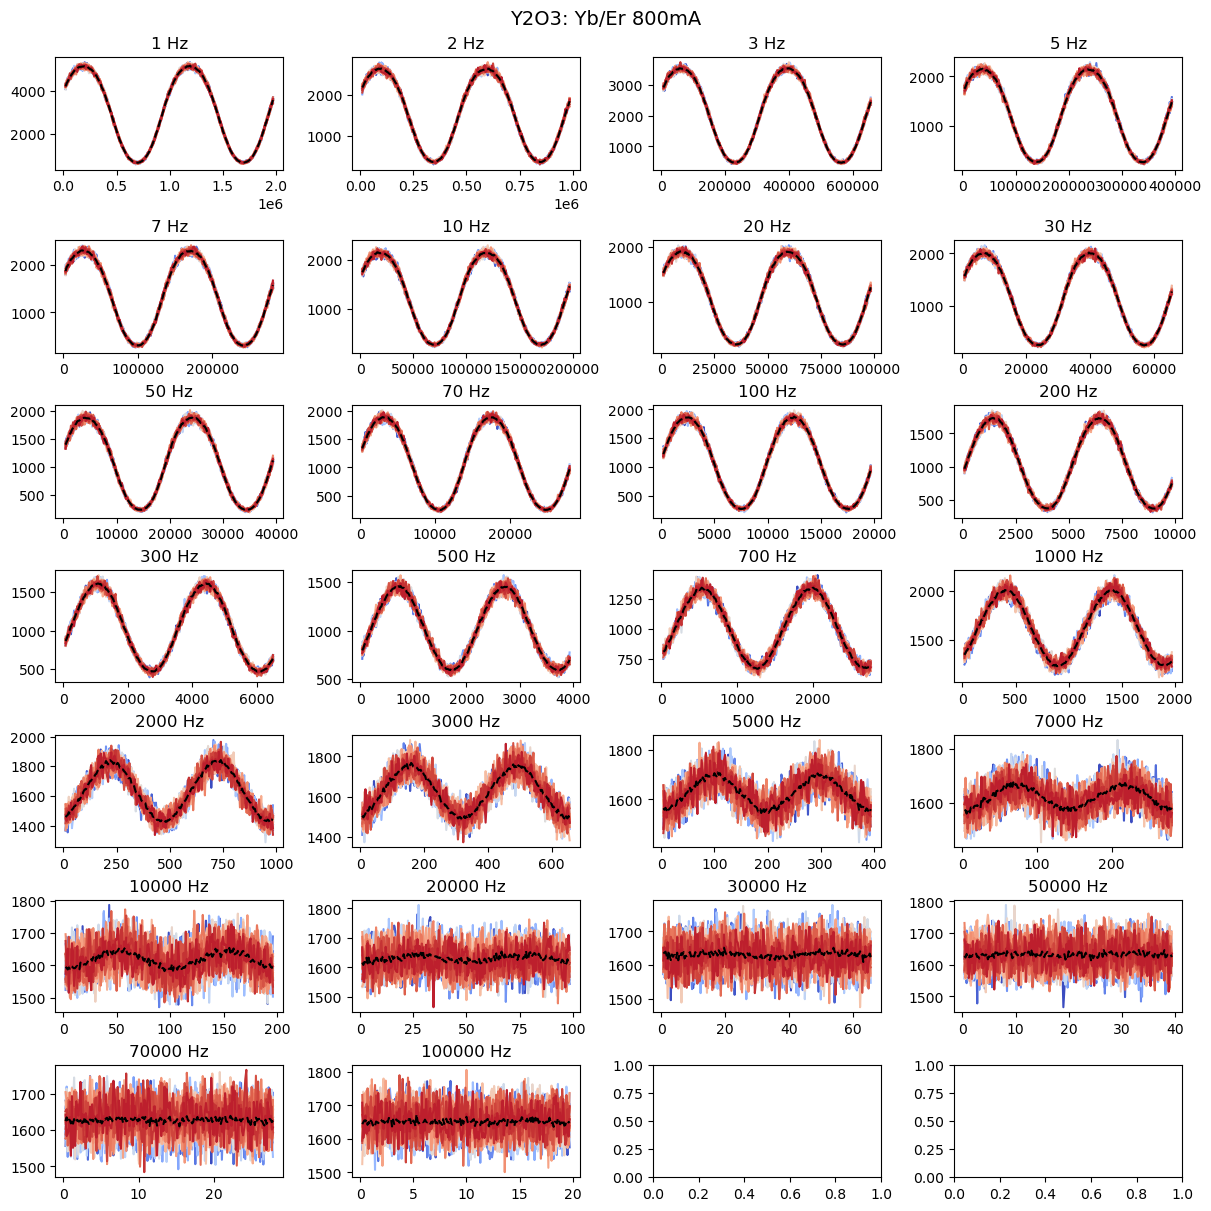

In [6]:
time_domain_visual_verification(
    samples_list,
    # samples_off=[i for i in range(len(samples_list)) if (i != 0)],
    show_mean=True,
)


  Processing Laser  


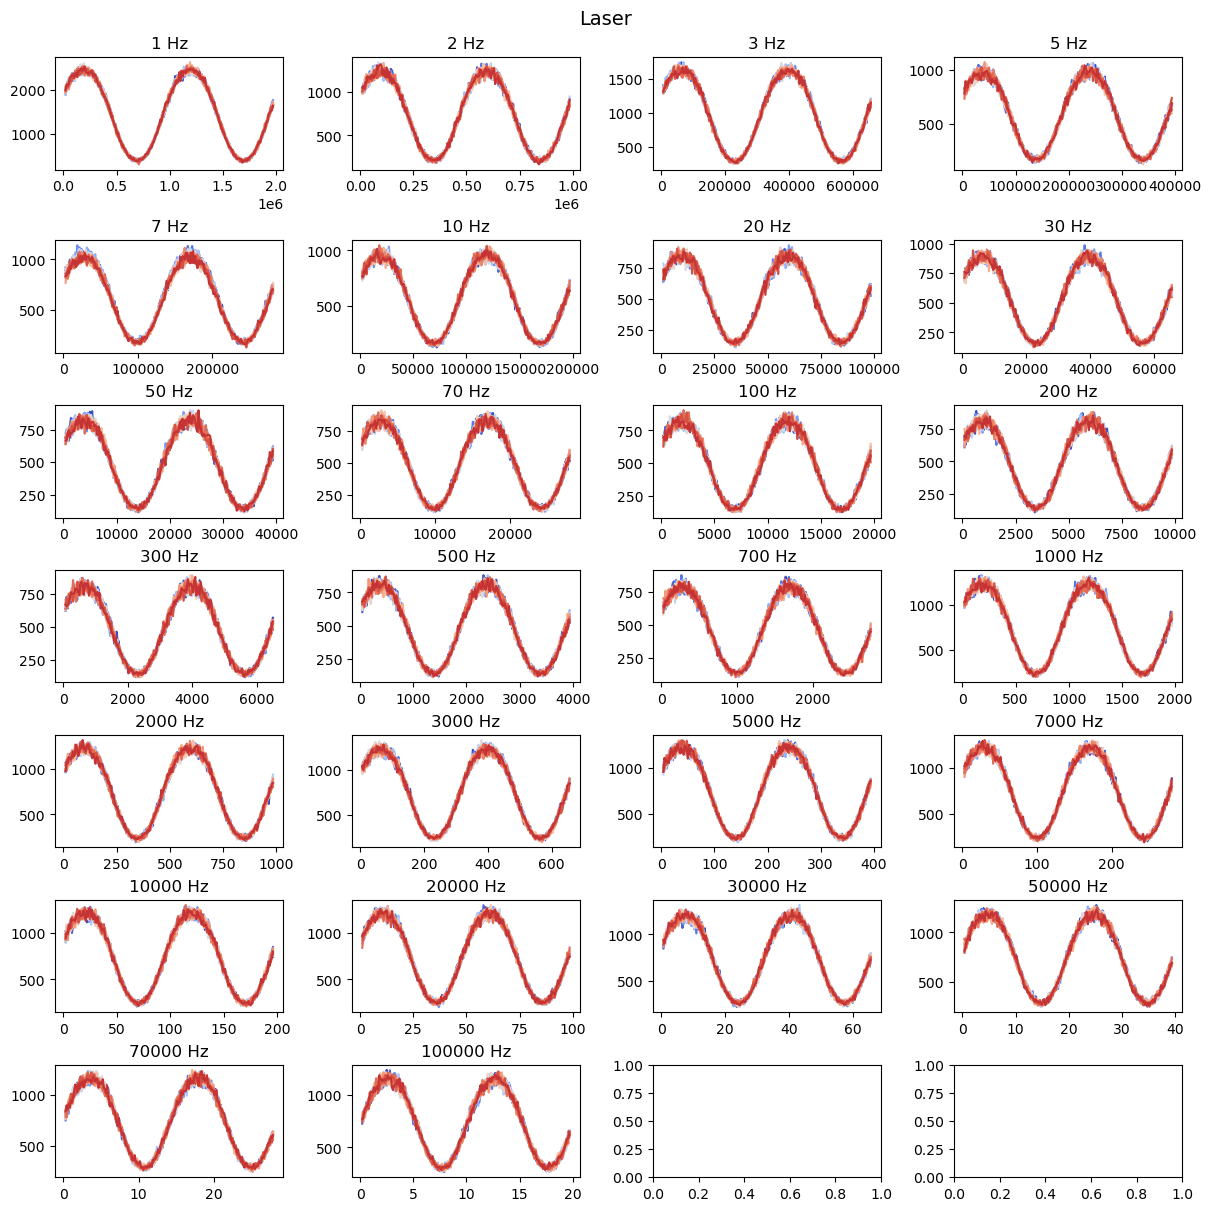

In [7]:
# Excitation
time_domain_visual_verification(
    [
        {
            "sample_label": "Laser",
            "sample_data": exc_data_npy
        }
    ]
)

## Get mean phases and errors


In [8]:
# Calculate list of phasors for the laser and all measurements
for step in exc_data_npy:
    freq = step["freq"]
    step["fft_amp_list"] = []
    for meas_idx, meas in enumerate(step["data"]):
        _, amp = get_xf_yf_fund(meas[:, 0], meas[:, 1], freq)
        step["fft_amp_list"].append(amp)

In [9]:
# Get mean phase and error for each particle and each step (freq)
for step in exc_data_npy:
    freq = step["freq"]
    amp_list = step["fft_amp_list"]
    _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
    step["mean_fft_info"] = [freq, phase, phase_error]

In [10]:
# Calculate list of phasors for all particles and all measurements
for sample in samples_list:
    for step in sample["sample_data"]:
        freq = step["freq"]
        step["fft_amp_list"] = []
        for meas_idx, meas in enumerate(step["data"]):
            _, amp = get_xf_yf_fund(meas[:, 0], meas[:, 1], freq)
            step["fft_amp_list"].append(amp)

In [11]:
# Get mean phase and error for each particle and each step (freq)
for sample in samples_list:
    for step in sample["sample_data"]:
        freq = step["freq"]
        amp_list = step["fft_amp_list"]
        _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
        step["mean_fft_info"] = [freq, phase, phase_error]

## Comparison — all particles


In [12]:
def get_error_bar(exc_data, samples_list):
    exc_mean_phase = np.array(
        [
            step["mean_fft_info"]
            # [freq, phase, phase_error]
            for step in exc_data
        ]
    )
    # error_exc = exc_mean_phase[:, 2]
    # print(error_exc)

    for sample in samples_list:
        # if p["p_label"] !=2: continue
        sample_mean_phase = np.array([step["mean_fft_info"] for step in sample["sample_data"]])

        if (sample_mean_phase[:, 0] - exc_mean_phase[:, 0]).sum() != 0.0:
            print("Deu ruim!")
            return None
        else:
            pd_list = np.unwrap(sample_mean_phase[:, 1] - exc_mean_phase[:, 1])
            pd_error = np.hypot(sample_mean_phase[:, 2], exc_mean_phase[:, 2])

        sample["error_bar"] = np.column_stack((sample_mean_phase[:, 0], pd_list, pd_error))


get_error_bar(exc_data_npy, samples_list)

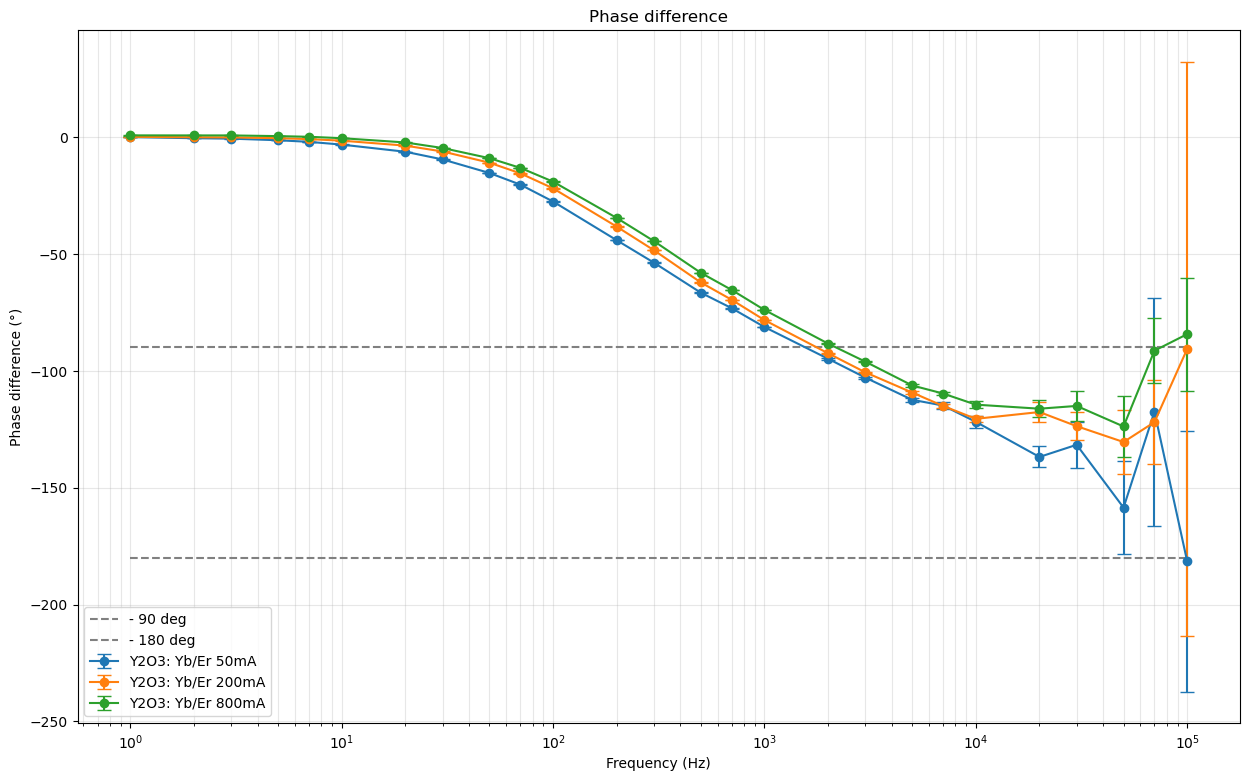

In [13]:
def plot_phase_difference(samples: list, samples_to_skip=[], freqs_to_skip=[]):
    plt.figure(figsize=(15, 9))

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for sample_id, sample in enumerate(samples):
        if sample_id in samples_to_skip:
            continue
        color = colors[sample_id % len(colors)]

        data = np.asarray(sample["error_bar"])           # colunas: freq, fase, erro
        data = data[~np.isin(data[:, 0], freqs_to_skip)] # remove as frequências puladas
        data = data[np.argsort(data[:, 0])]              # ordena por frequência
        
        if data.size == 0:
            continue
        freqs, phases, errors = data.T

        plt.errorbar(
            freqs,
            np.rad2deg(phases),
            yerr=np.rad2deg(errors),
            label=f"{sample['sample_label']}",
            fmt="o-",
            capsize=5,
            color=color,
        )

    plt.hlines(-90, xmin=freqs[0], xmax=freqs[-1], linestyles="--", colors="gray", label="- 90 deg")
    plt.hlines(-180, xmin=freqs[0], xmax=freqs[-1], linestyles="--", colors="gray", label="- 180 deg")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Phase difference (°)")
    plt.xscale("log")
    plt.title("Phase difference")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.show()

plot_phase_difference(
    samples_list,
    # samples_to_skip=[i for i in range(1, 31) if (i != 1) and (i != 2)],
    # freqs_to_skip = freq_list[-2:],
)